# PTM3D Tutorial 02 — Europa surface thermal, with a Jupiter eclipse

A self-contained walkthrough of PTM3D's Europa quickstart: one full Europa
"day" (one orbit around Jupiter, 3.55 Earth days — Europa is tidally locked,
so the orbit period *is* the diurnal period) of surface temperature over the
entire moon on a coarse global mesh. It follows the same structure and reader
code as [`01_moon_diurnal.ipynb`](01_moon_diurnal.ipynb) and the lunar
tutorial [`02_lunar_diurnal_icosphere.md`](../02_lunar_diurnal_icosphere.md).

## What you'll learn

- The Europa-specific config blocks: `body: Europa` (built-in ephemeris +
  ice-regolith thermal defaults), Jupiter as the **primary body** (reflected
  light *and* thermal IR — two physically distinct, separately-gated terms),
  and why `duration_days: 3.55` is Europa's whole diurnal cycle.
- How to run `ptm_thermal_sim` from Python and stream its progress.
- The on-disk output format (`statistics/*.bin`, per-timestep snapshots,
  `mesh.ply` with per-face lat/lon), read with the Python standard library
  and NumPy.
- How to choose a color scale for a planetary temperature field, and how to
  draw the result on orthographic globes with matplotlib alone.
- How to tell an incompletely equilibrated run from real surface structure.
- The **Jupiter eclipse**: once per orbit, Europa passes through Jupiter's
  shadow and direct solar flux drops to exactly zero, body-wide, for ~2.7
  hours. This run's `start_time` is chosen so the output window captures one.
- Why Europa's night side stays much *warmer relative to its day side* than
  the Moon's does, despite broadly comparable regolith thermal inertia.

**Cost:** CPU-only. The main run takes roughly 10 s on a many-core
workstation (measured below) and about a minute on a modest laptop; the
whole notebook runs the engine twice and stays under 1 GB RAM. The mesh is a 5120-face
icosphere with radiation exchange off (a convex sphere has no self-view), so
no GPU and no view-factor matrix are involved.

**Prerequisite:** a built `ptm_thermal_sim` binary and the Europa SPICE
kernels, which (unlike the Moon's) include the 1.1 GB Galilean-satellite
ephemeris `jup365.bsp` — Europa's position *relative to Jupiter* is what
produces the eclipse. The next cell checks for both and prints the command to
run if either is missing.

## 0. Environment check

Checks, in order: Python version, `numpy` and `matplotlib`, the
`ptm_thermal_sim` binary, and — Europa-specific — **both** SPICE kernel
pieces: the generic leapseconds/planetary kernels every body needs, and the
Galilean ephemeris only the Jovian moons need. Each failure prints the
command that fixes it.


In [1]:
import sys

print(f"Python {sys.version.split()[0]} ({sys.executable})")
if sys.version_info < (3, 8):
    print(f"WARNING: PTM3D's own helper scripts need Python >= 3.8 "
          f"(README 'Prerequisites' table); you have {sys.version_info}.")

missing = []
try:
    import numpy as np
    print(f"numpy      {np.__version__}  OK")
except ImportError:
    missing.append("numpy")
    print("numpy      MISSING")

try:
    import matplotlib
    import matplotlib.pyplot as plt
    print(f"matplotlib {matplotlib.__version__}  OK")
except ImportError:
    missing.append("matplotlib")
    print("matplotlib MISSING")

if missing:
    print()
    print("Missing required package(s):", ", ".join(missing))
    print(f"  Proposed fix: {sys.executable} -m pip install {' '.join(missing)}")
    raise ImportError(
        f"Install the package(s) above, then Kernel > Restart and re-run: {missing}"
    )

# PyYAML is optional: it gives a structured view of the config in section 1;
# without it the raw YAML text is shown instead.
try:
    import yaml
    HAVE_YAML = True
    print(f"PyYAML     {yaml.__version__}  OK (optional)")
except ImportError:
    HAVE_YAML = False
    print("PyYAML     not found (optional) -- config walkthrough will show")
    print(f"           raw YAML text only. To enable structured display:")
    print(f"             {sys.executable} -m pip install pyyaml")


Python 3.8.18 (/Users/paha3326/anaconda3/envs/europa_viz/bin/python)
numpy      1.24.4  OK


matplotlib 3.7.5  OK
PyYAML     6.0.2  OK (optional)


In [2]:
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    '''Walk up from `start` looking for the PTM3D repo root.

    Works whether Jupyter was launched from the repo root or from this
    notebook's own directory (docs/tutorials/notebooks/).
    '''
    for cand in [start.resolve(), *start.resolve().parents]:
        if (cand / "CMakeLists.txt").exists() and (cand / "examples").is_dir():
            return cand
    raise RuntimeError(
        f"Could not locate the PTM3D repo root by walking up from {start}. "
        "Open this notebook from inside a PTM3D clone."
    )


REPO_ROOT = find_repo_root(Path.cwd())
print("Repo root:", REPO_ROOT)

BINARY = REPO_ROOT / "build" / "bin" / "ptm_thermal_sim"
CONFIG = REPO_ROOT / "examples" / "quickstart_europa_diurnal.yaml"
LSK_KERNEL = REPO_ROOT / "data" / "kernels" / "lsk" / "naif0012.tls"
JUP_KERNEL = REPO_ROOT / "data" / "kernels" / "spk" / "jup365.bsp"
METAKERNEL = REPO_ROOT / "data" / "kernels" / "europa.tm"

ok = True

if not CONFIG.exists():
    print(f"\nConfig not found at {CONFIG} -- is this really a PTM3D clone?")
    ok = False
else:
    print("Found config:", CONFIG)

if not BINARY.exists():
    ok = False
    print(f"\nptm_thermal_sim not found at {BINARY}.")
    print("Build it first (CPU-only) -- INSTALL.md TL;DR:")
    print()
    print("  export CSPICE_ROOT=/path/to/cspice")
    print("  cmake -S . -B build -DCMAKE_BUILD_TYPE=Release -DPTM_ENABLE_GPU=OFF \\")
    print("        -DPTM_ARCH_NATIVE=OFF -DCSPICE_ROOT=\"$CSPICE_ROOT\"")
    print("  cmake --build build --target ptm_thermal_sim -j")
else:
    print("Found binary:", BINARY)

if not METAKERNEL.exists():
    ok = False
    print(f"\nEuropa metakernel not found at {METAKERNEL} -- this ships with the repo; "
          "something is wrong with the checkout.")
else:
    print("Found metakernel:", METAKERNEL)

if not LSK_KERNEL.exists() or not JUP_KERNEL.exists():
    ok = False
    if not LSK_KERNEL.exists():
        print(f"\nSPICE leapseconds kernel not found at {LSK_KERNEL}.")
    if not JUP_KERNEL.exists():
        print(f"\nGalilean-satellite ephemeris not found at {JUP_KERNEL} "
              "(1.1 GB -- this is the Europa-specific piece; the Moon's kernel "
              "set does not need it).")
    print("Fetch the full Europa kernel set (core + jup365.bsp, ~1.1 GB total):")
    print("  python3 scripts/fetch_kernels.py --bodies europa")
    print("(Downloads are resumable; re-run the same command to verify -- see "
          "data/kernels/README.md. With several PTM3D checkouts on one machine, "
          "data/kernels/{lsk,pck,spk,fk} can be symlinked from an "
          "already-populated checkout instead of re-fetching.)")
else:
    print(f"Found SPICE kernels: lsk/naif0012.tls and spk/jup365.bsp "
          f"({JUP_KERNEL.stat().st_size / 1e9:.2f} GB).")

if not ok:
    raise FileNotFoundError(
        "Environment is not ready -- follow the printed commands above, "
        "then re-run this cell."
    )

print("\nEnvironment OK.")


Repo root: /Users/paha3326/Projects/ptm-tutv2
Found config: /Users/paha3326/Projects/ptm-tutv2/examples/quickstart_europa_diurnal.yaml
Found binary: /Users/paha3326/Projects/ptm-tutv2/build/bin/ptm_thermal_sim
Found metakernel: /Users/paha3326/Projects/ptm-tutv2/data/kernels/europa.tm
Found SPICE kernels: lsk/naif0012.tls and spk/jup365.bsp (1.14 GB).

Environment OK.


## 1. The config file

[`examples/quickstart_europa_diurnal.yaml`](../../../examples/quickstart_europa_diurnal.yaml)
drives everything below. Like the Moon quickstart it is deliberately small,
fast, and radiation-off. (The pre-existing `examples/europa_high_res.yaml` is
a production-scale ico7, GPU-targeted config — a reference for
full-resolution runs, not a laptop quickstart.)


In [3]:
config_text = CONFIG.read_text()
print(config_text)


# PTM3D quickstart: Europa diurnal (one orbit) run on a small icosphere (ico4, 5120 faces).
#
# Laptop-friendly (CPU-only, radiation off, < 1 GB RAM, seconds of wall time). All
# paths are relative — run FROM THE REPOSITORY ROOT after fetching SPICE kernels:
#
#     python3 scripts/fetch_kernels.py --bodies europa   # once, ~1.1 GB from NAIF
#     ./build/bin/ptm_thermal_sim --config examples/quickstart_europa_diurnal.yaml
#
# Europa is tidally locked, so one "diurnal cycle" IS one orbit around Jupiter
# (3.55 Earth days) — unlike the Moon, whose 29.53-day synodic day is much
# longer than its (irrelevant, for surface heating) sidereal rotation.
#
# start_time is pinned to 2025-01-01T00:00:00 deliberately: at this epoch a
# full Jupiter eclipse (Europa passing through Jupiter's shadow) falls at
# ~18:06-20:33 UTC on day 1, i.e. inside this run's single-orbit output
# window. Direct solar flux drops to exactly zero, body-wide, for ~2.7 h
# (6 of 192 output steps) — Europa's signature ph

In [4]:
if HAVE_YAML:
    import json
    cfg = yaml.safe_load(config_text)
    print(json.dumps(cfg, indent=2))
else:
    cfg = None
    print("(PyYAML not installed -- see the raw text above for the same information.)")


{
  "simulation": {
    "start_time": "2025-01-01T00:00:00",
    "duration_days": 3.55,
    "timesteps": 192,
    "body": "Europa"
  },
  "mesh": {
    "resolution": 4,
    "import_file": "",
    "scale_factor": 1.0,
    "use_topographic": false
  },
  "thermal": {
    "run_thermal_mesh": true,
    "threads": 0,
    "equilibration_orbits": 20.0,
    "use_gpu": false,
    "compute_statistics": true,
    "enable_shadow_flux": false,
    "crater_dd_ratio": 8.0
  },
  "thermophysical": {
    "use_default_albedo": true,
    "incidence_angle_albedo": true
  },
  "radiation": {
    "enabled": false
  },
  "illumination": {
    "include_primary_reflection": true,
    "use_batch_processing": true,
    "use_albedo_map": false,
    "albedo_maps_directory": "data/albedo_maps"
  },
  "output": {
    "directory": "output/quickstart_europa_diurnal",
    "format": "binary",
    "vtk_mode": "none"
  },
  "advanced": {
    "verbose": false
  }
}


### Reading the blocks — what's Europa-specific

- **`simulation`** — `body: Europa` selects PTM3D's built-in Europa
  ephemeris, radius (1560.8 km), ice-regolith thermal defaults, **and**
  Jupiter as the primary body (via `europa.tm`'s `jup365.bsp` Galilean
  ephemeris — no separate config key names Jupiter). `duration_days: 3.55` is
  Europa's *entire* diurnal cycle (tidally locked: orbital period = rotation
  period), unlike the Moon's 29.53-day synodic month.
  `start_time: 2025-01-01T00:00:00` is chosen so the output window captures
  an eclipse (section 4).

- **`mesh`** — `resolution: 4` (5120 faces, ~250 km face pitch), one level
  finer than the Moon quickstart's `resolution: 3` to compensate for
  Europa's smaller radius (1560.8 km vs the Moon's 1737.4 km).

- **`thermal`** — `equilibration_orbits: 20.0` spins the model up for 20
  orbits before the output window opens. Europa's icy regolith has a thin
  diurnal skin depth (~5 cm — see the interpretation section), so the *surface*
  layer settles within an orbit or two, but the layers below it take far
  longer, and section 4.6 shows what an under-equilibrated deep column does to
  the temperature map. `use_gpu: false` keeps the run entirely on the CPU.

- **`thermophysical`** — `use_default_albedo: true` selects PTM3D's built-in
  Europa defaults (`thermal/planetary_properties.h`): Bond albedo **0.5**,
  emissivity **0.9**, thermal inertia $\Gamma\approx60$ SI
  ($k_s=0.0096$ W/m/K, $\rho_s=500$ kg/m³ porous ice regolith), internal
  heat flux $Q_b=0.03$ W/m². This is the "uniform ice" case — no spatial
  albedo map (`illumination.use_albedo_map: false`); the alternative
  (`configs/europa_ico6_albedo-map.yaml`) loads a FITS map instead.

- **`radiation.enabled: false`** — same reasoning as the Moon: a smooth
  convex sphere has no self-view, so there is nothing for the radiosity
  solver to do.

- **`illumination` — the two Jupiter terms.** Europa receives *three* flux
  components: direct sunlight, sunlight reflected off Jupiter
  ("Jupiter-shine"), and Jupiter's own thermal IR emission. These are
  **separately gated**:
  - `include_primary_reflection: true` controls *only* the reflected-light
    term (`calculatePrimaryReflectedBatch`).
  - Jupiter's thermal IR (`calculatePrimaryIRBatch`) runs **unconditionally**
    whenever the body has a non-Sun primary; `include_primary_reflection`
    does **not** gate it. Setting it `false` removes Jupiter-shine but
    leaves Jupiter's IR heating in place. See Exercise 3.
  - `use_batch_processing: true` is a performance path (batched ray
    queries), not a physics toggle.
  - `use_albedo_map: false` uses one uniform Bond albedo for the whole
    moon. Section 1 of `examples/quickstart_europa_albedo_map.yaml` replaces it
    with Europa's observed albedo map.

- **`output`** — `directory: output/quickstart_europa_diurnal`,
  `format: binary`, `vtk_mode: none` (this notebook reads the raw `.bin`
  files directly). A separate, easily-confused flag,
  `output.include_primary_ir` (default off, not set here), controls only
  whether primary IR is written into the *VTK* output; it has no effect on
  the physics or on the per-timestep `primary_ir/*.bin` files read below —
  this run writes all 192 per-step files with the flag at its default.

## 2. Run the simulation

**Expected wall time: ~10-15 s** on a many-core workstation (measured below),
up to a minute or two on a 2-4 core laptop — it threads over whatever cores
are available (`thermal.threads: 0` = auto-detect).

The cell below streams the engine's stdout live but **throttles the two
carriage-return progress readouts to roughly every 25%** so the executed
notebook stays readable; every non-progress line (mesh size, albedo model,
thread count, final flux/temperature summary) is shown in full.


In [5]:
import subprocess
import time
import re

cmd = [str(BINARY), "--config", str(CONFIG)]
print("Running:", " ".join(cmd))
print(f"(cwd={REPO_ROOT})\n")

progress_pct_re = re.compile(r"\]\s*(\d+)%")
progress_step_re = re.compile(r"Progress (\d+)/(\d+)")
last_pct_shown = -1
last_step_shown = -1
lines_seen = 0

t0 = time.time()
proc = subprocess.Popen(
    cmd, cwd=str(REPO_ROOT),
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    text=True, bufsize=1, universal_newlines=True,
)

for raw_line in iter(proc.stdout.readline, ""):
    line = raw_line.rstrip()
    if not line:
        continue
    lines_seen += 1

    m_pct = progress_pct_re.search(line)
    if m_pct:
        pct = int(m_pct.group(1))
        if pct in (0, 100) or pct - last_pct_shown >= 25:
            print(line)
            last_pct_shown = pct
        continue

    m_step = progress_step_re.search(line)
    if m_step:
        step, total = int(m_step.group(1)), int(m_step.group(2))
        if step == total or step - last_step_shown >= max(total // 4, 1):
            print(line)
            last_step_shown = step
        continue

    print(line)

proc.wait()
wall_time_s = time.time() - t0

print(f"\n--- {lines_seen} raw output lines seen; wall time {wall_time_s:.1f} s; "
      f"exit code {proc.returncode} ---")
if proc.returncode != 0:
    raise RuntimeError(f"ptm_thermal_sim exited with code {proc.returncode} -- see output above")


Running: /Users/paha3326/Projects/ptm-tutv2/build/bin/ptm_thermal_sim --config /Users/paha3326/Projects/ptm-tutv2/examples/quickstart_europa_diurnal.yaml
(cwd=/Users/paha3326/Projects/ptm-tutv2)

    ╔═══════════════════════════════════════════════════════════════╗
    ║    *      .    *     \   ||    //      * .   .      *         ║
    ║       .      *     \  \  ||   //    //       .             .  ║
    ║  *      .       \   \  \  ☀  //    //      .      *           ║
    ║     .         *  \   ...-'''''-...//    *         .           ║
    ║           _ ... .-'''''   PTM3D     ``''-.....,__      .      ║
    ║   __,.-''    Planetary Thermophysical Model 3D     `'-..., _  ║
    ║  ═══════════════════════════════════════════════════════════  ║
    ║      Coupled Thermal-Illumination for Planetary Bodies        ║
    ╚═══════════════════════════════════════════════════════════════╝
Successfully loaded configuration from: /Users/paha3326/Projects/ptm-tutv2/examples/quickstart_europa_di

========== Thermal Equilibration Configuration ==========
Body: Europa
Synodic day (solar day): 3.55 Earth days
Equilibration cycles: 20.00 day/night cycles
Total equilibration period: 71.00 Earth days
Output window (for export): 3.55 Earth days
Requested integration (stats): 3.55 days with offset 0.00 days
Post-equilibration simulated span: 3.55 Earth days
Total simulation time: 74.55 Earth days
Time step calculation:
  Requested output time steps: 192
  Output window (days): 3.55
  Output cadence:        54.084507 steps/Earth-day
  Equilibration cadence: 54.084507 steps/Earth-day [legacy (matches output cadence)]
  Total simulation days: 74.550000
  Equilibration steps: 3840
  Output steps:        192
  Total time steps (including equilibration and integration coverage): 4032
Running illumination simulation for 74.550000 days (including 71.000000 days equilibration) starting at 2024-10-22T00:00:00
[IlluminationModel] mesh topology: CLOSED (watertight) (0 boundary edges / 7680 unique 

[IlluminationModel] Embree scene ready. V=2562 F=5120 origin shift=(0.000000, 0.000000, 0.000000)


[illumination] NOTE: primary-disk probe found no above-horizon sample on a face whose analytic horizon clip is still positive (a ~sin^3(alpha)/2 sliver at the bottom of the band). Keeping the analytic, unoccluded value there; the flux involved is ~0. Warned once.
Calculating illumination:  [>                                                 ] 0% | elapsed 0s


Calculating illumination:  [============>                                     ] 25% | elapsed 1s, ETA 4s


Calculating illumination:  [=========================>                        ] 50% | elapsed 3s, ETA 3s


... (9 outputs left out)

  Progress 109/192


  Progress 163/192
  Progress 192/192
  Export complete: 192/192
Binary export completed successfully!
Data successfully written in binary format to: output/quickstart_europa_diurnal
[Statistics] Exporting statistics over integration window...
[exportStatisticsBinary] Computing and exporting statistics...
  Face count: 5120
  Time steps: 192
  Computing illumination statistics...
  Computing direct solar statistics...
  Computing primary reflected statistics...
  Computing primary IR statistics...
  Computing temperature statistics...
[exportStatisticsBinary] Statistics export completed successfully!
[Statistics] Exported to output/quickstart_europa_diurnal/statistics
[albedo] PTM-107(a) effective surface albedo (flux-weighted over the DIRECT beam, the value the BC absorbed with): global A_eff = 0.56723 over 5116/5120 ever-lit faces; per-face -> output/quickstart_europa_diurnal/statistics/effective_albedo.bin (uint32 n + float32[5120], NaN where never lit).
          Reduced over the I

Results:
  Average total flux: 16.573898360 W/m^2
    - Direct solar: 16.490930009 W/m^2
    - Primary reflected: 0.017158713 W/m^2
    - Primary IR: 0.048650925 W/m^2
  Maximum total flux: 52.758116490 W/m^2
    - Direct solar: 52.758116490 W/m^2
    - Primary reflected: 0.132681643 W/m^2
    - Primary IR: 0.153794674 W/m^2
  Minimum flux (non-zero): 0.000000000 W/m^2
  Output written to output/quickstart_europa_diurnal
Performing memory cleanup...


Memory cleanup completed.
Cleaning up remaining memory...
Cleanup completed successfully

--- 355 raw output lines seen; wall time 9.7 s; exit code 0 ---


## 3. Output tour

```
output/quickstart_europa_diurnal/
├── mesh.ply               # the 5120-face icosphere; face order matches every .bin file
├── metadata.txt            # faces, time_steps, exported components
├── time_steps.txt          # per-step time stamp (SPICE ET + a UTC label column)
├── body_positions.csv      # Sun AND Jupiter vectors per output step (Europa-specific
│                            #   second target -- see below)
├── statistics/              # 16 files: {temperature,illumination,direct_solar,
│                            #   primary_reflected,primary_ir}_{min,avg,max}.bin
│                            #   + effective_albedo.bin, reduced over the 192-step
│                            #   *output* window only (5 equilibration orbits excluded)
├── temperature/              # temperature_0000.bin .. temperature_0191.bin (per-step)
├── illumination/              #   total absorbed flux per step
├── direct_solar/               #   direct solar component
├── primary_reflected/           #   Jupiter-reflected sunlight ("Jupiter-shine")
└── primary_ir/                   #   Jupiter's own thermal IR emission
```

`body_positions.csv` has **two** target vectors per row (unlike the Moon's
one) — `sun_x/y/z` and `primary_x/y/z`, both in km, as seen from Europa's
center. Their magnitudes are checked below: `sun_*` should be of order
Europa's ~5.2 AU heliocentric distance ($\approx7.5\times10^8$ km), and
`primary_*` of order Europa's Jupiter-orbit radius (671,100 km,
`constants.cpp`'s `EUROPA_ORBIT_RADIUS`).

### Binary format

Every `.bin` file (both `statistics/*.bin` and the per-timestep snapshots)
is a 4-byte little-endian face-count header followed by that many
little-endian `float32` values, one per mesh face, in mesh-face order (full
table: [`06_interpreting_outputs.md`](../06_interpreting_outputs.md)).


In [6]:
import struct
import numpy as np

OUT_DIR = REPO_ROOT / "output" / "quickstart_europa_diurnal"


def load_bin(path: Path) -> np.ndarray:
    '''Read one PTM3D statistics/ or per-timestep .bin file (see format
    above). Raises if the file is short/truncated instead of silently
    returning a partial array.'''
    raw = path.read_bytes()
    n = struct.unpack_from("<I", raw, 0)[0]
    expected = 4 + 4 * n
    if len(raw) != expected:
        raise ValueError(f"{path}: header says n={n} faces ({expected} bytes), "
                          f"file is {len(raw)} bytes -- truncated or wrong format")
    return np.frombuffer(raw, dtype="<f4", count=n, offset=4)


def load_mesh(path: Path):
    '''Read mesh.ply (PTM3D's own binary_little_endian writer).

    Layout:
      element vertex N: 6 x float64 (x, y, z, nx, ny, nz) [km; normals
                          written as 0 here, unused downstream]
      element face   M: uchar vertex-count + that-many x int32 vertex
                          indices (returned as `tris`, used by the globe
                          views in section 4.5), then float32 latitude,
                          float32 longitude (degrees) -- per-face values.
    All M faces have vertex-count == 3 in this mesh (a pure-triangle
    icosphere), checked below before one vectorized structured read.
    '''
    data = path.read_bytes()
    marker = b"end_header\n"
    header_end = data.index(marker) + len(marker)
    header = data[:header_end].decode("ascii")
    nv = int(re.search(r"element vertex (\d+)", header).group(1))
    nf = int(re.search(r"element face (\d+)", header).group(1))

    vertex_dtype = np.dtype([("x", "<f8"), ("y", "<f8"), ("z", "<f8"),
                              ("nx", "<f8"), ("ny", "<f8"), ("nz", "<f8")])
    verts = np.frombuffer(data, dtype=vertex_dtype, count=nv, offset=header_end)

    off = header_end + vertex_dtype.itemsize * nv
    first_vcount = data[off]
    if first_vcount != 3:
        raise NotImplementedError(
            f"mesh.ply face 0 has {first_vcount} vertices, not a triangle -- "
            "this reader only handles the pure-triangle icosphere case."
        )
    face_dtype = np.dtype([("n", "u1"), ("idx", "<i4", (3,)),
                            ("lat", "<f4"), ("lon", "<f4")])
    faces = np.frombuffer(data, dtype=face_dtype, count=nf, offset=off)
    if off + face_dtype.itemsize * nf != len(data):
        raise ValueError("mesh.ply: bytes remain after parsing all faces -- "
                          "format assumption above no longer holds")

    return (verts, faces["idx"].astype(np.int64), faces["lat"].copy(),
            faces["lon"].copy())


verts, tris, lat, lon = load_mesh(OUT_DIR / "mesh.ply")
n_lat_distinct = len(np.unique(np.round(lat, 3)))
n_lon_distinct = len(np.unique(np.round(lon, 3)))
print(f"mesh.ply: {len(verts)} vertices, {len(lat)} faces")
print(f"  latitude  range [{lat.min():.1f}, {lat.max():.1f}] deg, "
      f"{n_lat_distinct} distinct values")
print(f"  longitude range [{lon.min():.1f}, {lon.max():.1f}] deg, "
      f"{n_lon_distinct} distinct values")
print("  (fewer distinct latitudes than faces is icosahedral symmetry: "
      "many faces share the same |lat| band.)")

mesh.ply: 2562 vertices, 5120 faces
  latitude  range [-87.5, 87.5] deg, 1283 distinct values
  longitude range [-178.7, 180.0] deg, 2524 distinct values
  (fewer distinct latitudes than faces is icosahedral symmetry: many faces share the same |lat| band.)


In [7]:
import csv

with open(OUT_DIR / "body_positions.csv") as f:
    rows = list(csv.DictReader(f))
print(f"body_positions.csv: {len(rows)} rows, columns: {list(rows[0].keys())}")

sun_mag = np.array([np.linalg.norm([float(r["sun_x"]), float(r["sun_y"]), float(r["sun_z"])])
                     for r in rows])
primary_mag = np.array([np.linalg.norm([float(r["primary_x"]), float(r["primary_y"]), float(r["primary_z"])])
                         for r in rows])
AU_KM = 1.495978707e8
print(f"|sun vector|:     {sun_mag.min():.3e} - {sun_mag.max():.3e} km "
      f"({sun_mag.mean()/AU_KM:.2f} AU mean -- Europa's heliocentric distance is ~5.2 AU)")
print(f"|primary vector|: {primary_mag.min():.0f} - {primary_mag.max():.0f} km "
      f"(Europa's Jupiter-orbit radius is 671,100 km, constants.cpp EUROPA_ORBIT_RADIUS)")


body_positions.csv: 192 rows, columns: ['time', 'sun_x', 'sun_y', 'sun_z', 'primary_x', 'primary_y', 'primary_z']
|sun vector|:     7.598e+08 - 7.611e+08 km (5.08 AU mean -- Europa's heliocentric distance is ~5.2 AU)
|primary vector|: 664673 - 677487 km (Europa's Jupiter-orbit radius is 671,100 km, constants.cpp EUROPA_ORBIT_RADIUS)


In [8]:
stats = {}
for name in ("temperature_max", "temperature_min", "temperature_avg"):
    arr = load_bin(OUT_DIR / "statistics" / f"{name}.bin")
    stats[name] = arr
    n_distinct = len(np.unique(np.round(arr, 1)))
    print(f"{name:16s}  n={len(arr):5d}  min={arr.min():6.2f}  "
          f"median={np.median(arr):6.2f}  mean={arr.mean():6.2f}  "
          f"max={arr.max():6.2f} K   (n_distinct@0.1K={n_distinct}, "
          f"range={arr.max()-arr.min():.1f} K)")

n_floor_faces = int(np.sum(stats["temperature_max"] < 40.0))
print(f"\n{n_floor_faces}/{len(stats['temperature_max'])} faces "
      f"({100*n_floor_faces/len(stats['temperature_max']):.2f}%) never exceed 40 K "
      "even at their warmest recorded moment -- permanently-unlit near-polar "
      "faces at this coarse mesh resolution; see interpretation section.")


temperature_max   n= 5120  min= 29.78  median=125.58  mean=119.27  max=133.75 K   (n_distinct@0.1K=648, range=104.0 K)
temperature_min   n= 5120  min= 29.74  median= 89.40  mean= 86.40  max= 93.44 K   (n_distinct@0.1K=372, range=63.7 K)
temperature_avg   n= 5120  min= 29.76  median=102.74  mean= 98.50  max=108.39 K   (n_distinct@0.1K=479, range=78.6 K)

8/5120 faces (0.16%) never exceed 40 K even at their warmest recorded moment -- permanently-unlit near-polar faces at this coarse mesh resolution; see interpretation section.


For comparison, the Moon quickstart's equivalent numbers
(`quickstart_moon_diurnal.yaml`, ico3, 1280 faces;
[`02_lunar_diurnal_icosphere.md`](../02_lunar_diurnal_icosphere.md),
2026-08-05, v1.0.3, CPU-only): `temperature_max` median **369.8 K**,
`temperature_min` median **92.6 K**, `temperature_avg` median **208.1 K**.
Europa is colder everywhere (5.2 AU vs ~1 AU from the Sun dominates over the
albedo difference); the comparison that matters is the **day/night swing**,
in section 5.


## 4. Plots

Six views of this run: a spatial map of peak temperature, a global-flux time
series that locates the eclipse, a per-face diurnal curve through it, day/night
contrast against latitude, the same fields on orthographic globes, and a check
that the run is equilibrated.

### Choosing a color scale for a planetary temperature field

A global temperature field is badly served by a linear color scale, and the
reason is physics rather than taste. Radiative equilibrium puts the surface at
$T \propto (\cos i)^{1/4}$, and the quarter power flattens the entire
sub-solar hemisphere: at 30° from the sub-solar point the insolation is down
13% but the temperature is down only 3%. Most faces therefore sit within a few
kelvin of the peak while a thin polar tail occupies the rest of the range, so a
linear scale spends most of its colors on the tail and paints the bulk of the
body in one indistinguishable shade. The next cell measures that for this run.

Two changes fix it, and both are used throughout the notebook:

- **A perceptually uniform colormap** (`inferno`). Equal steps in the data
  become equal-looking steps in color, its lightness rises monotonically from
  black to pale yellow, and it stays readable in grayscale.
- **A color scale linear in $T^4$ rather than in $T$** (`flux_norm` below).
  $\sigma T^4$ is the emitted flux — the quantity the $(\cos i)^{1/4}$
  geometry compressed in the first place — so coloring by it undoes exactly
  that compression. The colorbar still reads in kelvin; its ticks are simply
  not evenly spaced.

Signed differences later in the notebook use a diverging map centered on zero
instead, so that "no change" is a neutral color and the sign is legible.

In [9]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "text.color": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "grid.color": "#e1e0d9",
    "font.size": 11,
})

# Sequential and perceptually uniform: equal temperature steps look like equal
# color steps, lightness climbs monotonically, and the map survives grayscale
# printing. Never a rainbow -- its uneven lightness invents structure.
CMAP_T = "inferno"
# Diverging, for signed differences drawn about zero.
CMAP_DIFF = "RdBu_r"
ACCENT_ORANGE = "#eb6834"
ACCENT_AQUA = "#1baf7a"
NEUTRAL_BAND = "#8d8c82"   # non-data color: event-window shading only

try:
    from matplotlib.colors import FuncNorm

    def flux_norm(values, lo_pct=1.0, hi_pct=100.0):
        """Color scale linear in T**4 (emitted flux) between two percentiles.

        Radiative equilibrium gives T proportional to the fourth root of the
        absorbed flux, so a temperature field is a compressed picture of the
        flux field. Coloring by T**4 undoes exactly that compression. The
        colorbar still reads in kelvin; its ticks are simply not evenly spaced.
        """
        return FuncNorm((lambda t: np.clip(t, 0.0, None) ** 4,
                         lambda y: np.clip(y, 0.0, None) ** 0.25),
                        vmin=float(np.percentile(values, lo_pct)),
                        vmax=float(np.percentile(values, hi_pct)))

except ImportError:                                   # matplotlib < 3.4
    from matplotlib.colors import PowerNorm
    print(f"NOTE: matplotlib {mpl.__version__} has no FuncNorm (added in 3.4);")
    print("      using PowerNorm(gamma=4) instead. It stretches the top of the")
    print("      range in the same direction but is not exactly linear in T**4.")

    def flux_norm(values, lo_pct=1.0, hi_pct=100.0):
        return PowerNorm(4.0, vmin=float(np.percentile(values, lo_pct)),
                         vmax=float(np.percentile(values, hi_pct)))


def clip_extend(values, norm):
    """Which ends of the color scale are clipped: for the colorbar's arrows."""
    below = bool(np.any(np.asarray(values) < norm.vmin))
    above = bool(np.any(np.asarray(values) > norm.vmax))
    return {(False, False): "neither", (True, False): "min",
            (False, True): "max", (True, True): "both"}[(below, above)]


def sym_norm(values, pct=99.0):
    """Symmetric limits about zero for a signed field, robust to a few outliers."""
    m = float(np.percentile(np.abs(values), pct))
    if not m > 0:
        m = float(np.max(np.abs(values))) or 1.0
    return mpl.colors.Normalize(vmin=-m, vmax=m)


# How much does a linear color scale actually compress this field?
_t = stats["temperature_max"]
_lo, _hi = float(_t.min()), float(_t.max())
_top_decile = float(np.mean(_t > _hi - 0.1 * (_hi - _lo)))
_q25, _q75 = np.percentile(_t, [25, 75])
_v0 = float(np.percentile(_t, 1))
_budget_linear = (_q75 - _q25) / (_hi - _lo)
_budget_flux = (_q75 ** 4 - _q25 ** 4) / (_hi ** 4 - _v0 ** 4)
print(f"temperature_max spans {_lo:.1f}-{_hi:.1f} K over {_t.size} faces")
print(f"  faces sitting in the top 10% of that range : {100 * _top_decile:.0f}%")
print(f"  colors spent on the middle 50% of faces    : "
      f"{100 * _budget_linear:.0f}% linear  ->  {100 * _budget_flux:.0f}% with flux_norm")
print(f"  faces below the 1st percentile ({_v0:.1f} K), drawn clipped: "
      f"{int(np.sum(_t < _v0))} of {_t.size}")

temperature_max spans 29.8-133.7 K over 5120 faces
  faces sitting in the top 10% of that range : 56%
  colors spent on the middle 50% of faces    : 18% linear  ->  45% with flux_norm
  faces below the 1st percentile (62.9 K), drawn clipped: 52 of 5120


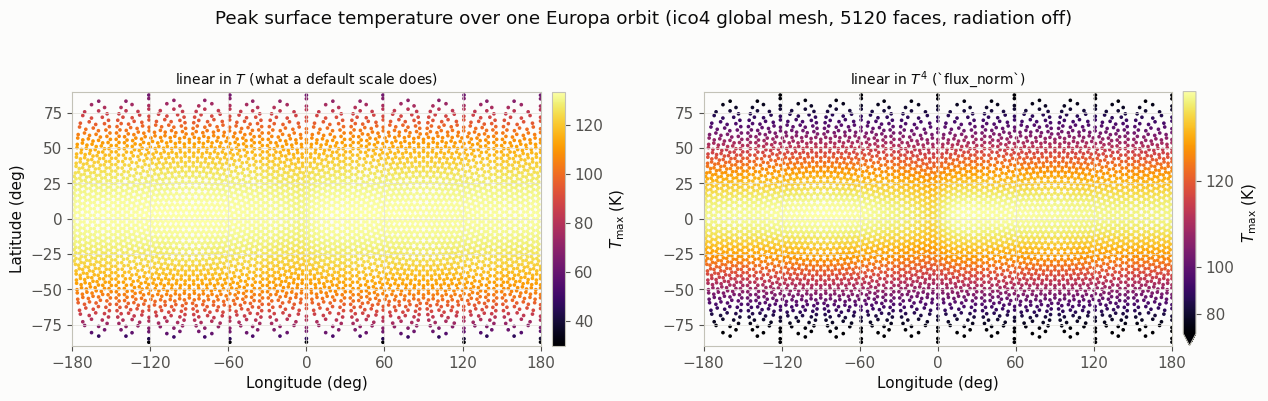

In [10]:
tmax = stats["temperature_max"]
norm_tmax = flux_norm(tmax)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, norm, label in ((axes[0], mpl.colors.Normalize(tmax.min(), tmax.max()),
                         "linear in $T$ (what a default scale does)"),
                        (axes[1], norm_tmax, "linear in $T^4$ (`flux_norm`)")):
    sc = ax.scatter(lon, lat, c=tmax, cmap=CMAP_T, norm=norm, s=7, linewidths=0)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xticks(range(-180, 181, 60))
    ax.set_xlabel("Longitude (deg)")
    ax.set_title(label, fontsize=10)
    ax.grid(True, linewidth=0.5)
    cb = fig.colorbar(sc, ax=ax, pad=0.02, extend=clip_extend(tmax, norm))
    cb.set_label(r"$T_\mathrm{max}$ (K)")
axes[0].set_ylabel("Latitude (deg)")
fig.suptitle(f"Peak surface temperature over one Europa orbit "
             f"(ico4 global mesh, {len(lat)} faces, radiation off)", y=1.02)
plt.tight_layout()
plt.show()

With the flux-linear scale the field reads as clean latitude bands, which is
what a smooth sphere of uniform ice should produce: every longitude gets the
same noon, so nothing distinguishes one meridian from another — except Jupiter,
which sits at a fixed longitude because Europa's rotation is synchronous.
Section 4.6 returns to this map, because how clean it looks turns out to depend
on a setting that has nothing to do with Europa.

### Locating the eclipse

An eclipse is a **global** event — the whole day side loses the Sun at once,
not a per-face terminator sweep — so the clearest signature is the **total
direct solar flux summed over all faces**. The cell below computes that sum
per output step and reports every step where it is exactly zero.


In [11]:
n_steps = cfg["simulation"]["timesteps"] if cfg else 192
direct_dir = OUT_DIR / "direct_solar"

global_direct = np.array([load_bin(direct_dir / f"direct_solar_{t:04d}.bin").sum()
                           for t in range(n_steps)])
n_lit = np.array([int(np.sum(load_bin(direct_dir / f"direct_solar_{t:04d}.bin") > 0.1))
                   for t in range(n_steps)])

eclipse_steps = np.where(global_direct < 1e-6)[0]
print(f"Global direct-solar flux: {global_direct.min():.1f} - {global_direct.max():.1f} W/m^2 "
      f"(summed over all {len(lat)} faces per step)")
print(f"n_lit faces per step (non-eclipse, non-fully-dark steps): "
      f"{n_lit[n_lit>0].min()} - {n_lit.max()} of {len(lat)}")
print(f"\nSteps with EXACTLY zero global direct flux (full-body eclipse): {list(eclipse_steps)}")
if len(eclipse_steps) == 0:
    raise RuntimeError(
        "No eclipse found in this run's output window -- the config's start_time "
        "no longer captures one (SPICE ephemeris/geometry may have changed, or "
        "the window/cadence shifted). The eclipse analysis below depends on "
        "this window."
    )

lines = [ln.split() for ln in (OUT_DIR / "time_steps.txt").read_text().splitlines()
         if ln.strip() and not ln.startswith("#")]
utc = [row[1] for row in lines]
print(f"\nEclipse window (UTC labels): {utc[eclipse_steps[0]]} -> {utc[eclipse_steps[-1]]}")
print(f"({len(eclipse_steps)} fully-dark output steps out of {n_steps}; true eclipse "
      "duration is somewhat longer than this, since the steps immediately before/after "
      "are already partway into ingress/egress)")


Global direct-solar flux: 0.0 - 67600.1 W/m^2 (summed over all 5120 faces per step)
n_lit faces per step (non-eclipse, non-fully-dark steps): 2546 - 2559 of 5120

Steps with EXACTLY zero global direct flux (full-body eclipse): [40, 41, 42, 43, 44, 45]

Eclipse window (UTC labels): 2025-01-01T18:10:37.657 -> 2025-01-01T20:23:47.138
(6 fully-dark output steps out of 192; true eclipse duration is somewhat longer than this, since the steps immediately before/after are already partway into ingress/egress)


### The eclipse's thermal fingerprint on one face

Pick the face with the highest direct-solar flux in the output step
*immediately before* the eclipse (a face near local noon at that moment —
the most dramatic case) and plot its full diurnal temperature curve, with
the eclipse window shaded.

Selected face: index 5058, lat=2.36 deg, lon=6.39 deg (direct solar 52.6 W/m^2 at step 39, just before ingress)


192 output steps spanning 84.8 h (3.53 d); cadence 0.44 h/step

Pre-eclipse local peak:  step 39  T=132.7 K  (flux=52.6 W/m^2)
Eclipse-window minimum:  step 45  T=109.0 K  (flux=0.0 W/m^2)
Post-eclipse local peak: step 54  T=128.9 K  (flux=46.0 W/m^2)

Cooling during eclipse: 23.7 K in 2.7 h


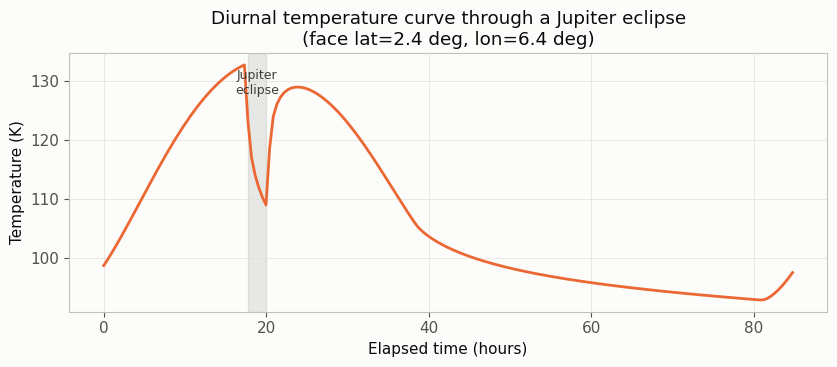

In [12]:
pre_eclipse_step = eclipse_steps[0] - 1
ds_pre = load_bin(direct_dir / f"direct_solar_{pre_eclipse_step:04d}.bin")
face = int(np.argmax(ds_pre))
print(f"Selected face: index {face}, lat={lat[face]:.2f} deg, lon={lon[face]:.2f} deg "
      f"(direct solar {ds_pre[face]:.1f} W/m^2 at step {pre_eclipse_step}, just before ingress)")

temp_dir = OUT_DIR / "temperature"
curve = np.array([load_bin(temp_dir / f"temperature_{t:04d}.bin")[face]
                   for t in range(n_steps)])
flux_curve = np.array([load_bin(direct_dir / f"direct_solar_{t:04d}.bin")[face]
                        for t in range(n_steps)])

t_et = np.array([float(row[0]) for row in lines])
t_hr = (t_et - t_et[0]) / 3600.0
cadence_hr = float(np.median(np.diff(t_hr)))
print(f"{len(t_hr)} output steps spanning {t_hr[-1]:.1f} h ({t_hr[-1]/24:.2f} d); "
      f"cadence {cadence_hr:.2f} h/step")

t_peak_before = curve[:eclipse_steps[0]].argmax()
t_trough = eclipse_steps[0] + curve[eclipse_steps[0]:eclipse_steps[-1]+1].argmin()
t_peak_after = eclipse_steps[-1] + 1 + curve[eclipse_steps[-1]+1:].argmax()
print(f"\nPre-eclipse local peak:  step {t_peak_before}  T={curve[t_peak_before]:.1f} K  "
      f"(flux={flux_curve[t_peak_before]:.1f} W/m^2)")
print(f"Eclipse-window minimum:  step {t_trough}  T={curve[t_trough]:.1f} K  "
      f"(flux={flux_curve[t_trough]:.1f} W/m^2)")
print(f"Post-eclipse local peak: step {t_peak_after}  T={curve[t_peak_after]:.1f} K  "
      f"(flux={flux_curve[t_peak_after]:.1f} W/m^2)")
print(f"\nCooling during eclipse: {curve[t_peak_before]-curve[t_trough]:.1f} K "
      f"in {(t_hr[t_trough]-t_hr[t_peak_before]):.1f} h")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(t_hr, curve, color=ACCENT_ORANGE, linewidth=2)
ax.axvspan(t_hr[eclipse_steps[0]], t_hr[eclipse_steps[-1]], color=NEUTRAL_BAND, alpha=0.18,
           zorder=0)
ymin, ymax = ax.get_ylim()
ax.text((t_hr[eclipse_steps[0]] + t_hr[eclipse_steps[-1]]) / 2, ymax - 0.06 * (ymax - ymin),
        "Jupiter\neclipse", ha="center", va="top", fontsize=9, color="#3d3c37")
ax.set_xlabel("Elapsed time (hours)")
ax.set_ylabel("Temperature (K)")
ax.set_title(f"Diurnal temperature curve through a Jupiter eclipse\n"
             f"(face lat={lat[face]:.1f} deg, lon={lon[face]:.1f} deg)")
ax.grid(True, linewidth=0.5)
plt.tight_layout()
plt.show()


## Day/night contrast — and the cross-reference to the Moon

The plot below is Europa's version of the Moon notebook's "day/night
contrast vs. latitude" plot ($T_\mathrm{max}-T_\mathrm{min}$ per face). The
interpretation section quantifies the cross-body comparison explicitly.

day/night contrast (Tmax-Tmin): min=0.0  max=41.7  median=36.0  mean=32.9 K  (n_distinct@0.1K=377, range=41.6 K)
correlation with |latitude|: r = -0.95


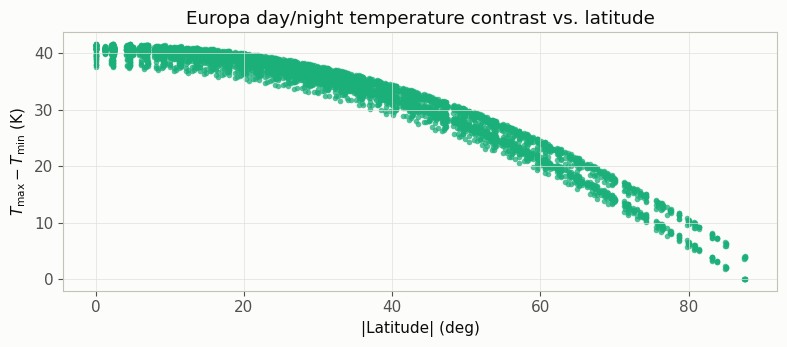


Median-face day/night swing:
  Moon   (cited, not re-run here): 369.8 - 92.6 K = 277.2 K swing, Tmin/Tmax = 0.25
  Europa (this run):               125.6 - 89.4 K = 36.2 K swing, Tmin/Tmax = 0.71


In [13]:
contrast = stats["temperature_max"] - stats["temperature_min"]
n_distinct_contrast = len(np.unique(np.round(contrast, 1)))
corr = float(np.corrcoef(np.abs(lat), contrast)[0, 1])
print(f"day/night contrast (Tmax-Tmin): min={contrast.min():.1f}  "
      f"max={contrast.max():.1f}  median={np.median(contrast):.1f}  mean={contrast.mean():.1f} K  "
      f"(n_distinct@0.1K={n_distinct_contrast}, range={contrast.max()-contrast.min():.1f} K)")
print(f"correlation with |latitude|: r = {corr:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(np.abs(lat), contrast, color=ACCENT_AQUA, s=16, alpha=0.75, linewidths=0)
ax.set_xlabel("|Latitude| (deg)")
ax.set_ylabel(r"$T_\mathrm{max} - T_\mathrm{min}$ (K)")
ax.set_title("Europa day/night temperature contrast vs. latitude")
ax.grid(True, linewidth=0.5)
plt.tight_layout()
plt.show()

moon_tmax_med, moon_tmin_med = 369.8, 92.6  # docs/tutorials/02_lunar_diurnal_icosphere.md, v1.0.3, 2026-08-05
europa_tmax_med = float(np.median(stats["temperature_max"]))
europa_tmin_med = float(np.median(stats["temperature_min"]))
print(f"\nMedian-face day/night swing:")
print(f"  Moon   (cited, not re-run here): {moon_tmax_med:.1f} - {moon_tmin_med:.1f} K "
      f"= {moon_tmax_med-moon_tmin_med:.1f} K swing, Tmin/Tmax = {moon_tmin_med/moon_tmax_med:.2f}")
print(f"  Europa (this run):               {europa_tmax_med:.1f} - {europa_tmin_med:.1f} K "
      f"= {europa_tmax_med-europa_tmin_med:.1f} K swing, Tmin/Tmax = {europa_tmin_med/europa_tmax_med:.2f}")


### 4.5 Globe views

The lat/lon scatter is an equirectangular projection: it stretches the poles
across the full width of the plot and cuts the body open at ±180°.
Orthographic globes show the field as a distant camera would see it — no
distortion at the center of the disk, each pole in a panel of its own, and no
seam. For a tidally locked moon the natural viewpoints are the sub-Jupiter
meridian (0° longitude), the anti-Jupiter meridian (180°) and the two poles.

`globe()` in the next cell is matplotlib-only. It averages the per-face
temperatures onto the mesh vertices, projects the vertices orthographically
for a chosen viewpoint, keeps the triangles whose three vertices all face the
viewer, and lets `tripcolor(..., shading="gouraud")` interpolate linearly
across each triangle. Nothing is resampled onto a raster grid, so the picture
is the mesh's own field, smoothed only by that interpolation. A 30° graticule
gives the orientation.

In [14]:
def face_unit_vectors(lat_deg, lon_deg):
    """Unit vectors of the face centers, from the per-face lat/lon in mesh.ply."""
    la = np.radians(np.asarray(lat_deg, dtype=float))
    lo = np.radians(np.asarray(lon_deg, dtype=float))
    return np.stack([np.cos(la) * np.cos(lo),
                     np.cos(la) * np.sin(lo),
                     np.sin(la)], axis=1)


def vertex_values_from_faces(tris, face_values, n_vertices):
    """Average a per-face field onto the mesh vertices (each vertex is shared by
    5 or 6 triangles on an icosphere)."""
    total = np.zeros(n_vertices)
    count = np.zeros(n_vertices)
    for k in range(3):
        np.add.at(total, tris[:, k], face_values)
        np.add.at(count, tris[:, k], 1.0)
    if count.min() == 0:
        raise ValueError("mesh.ply has a vertex that no face references -- "
                         "the globe interpolation below assumes a closed mesh")
    return total / count


def view_basis(view_lat, view_lon):
    """Orthonormal (toward-viewer, right, up) basis for an orthographic view."""
    la, lo = np.radians(view_lat), np.radians(view_lon)
    toward = np.array([np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)])
    right = np.cross([0.0, 0.0, 1.0], toward)
    if np.linalg.norm(right) < 1e-9:          # looking straight down a pole
        right = np.array([0.0, 1.0, 0.0])
    right /= np.linalg.norm(right)
    return toward, right, np.cross(toward, right)


def _graticule(ax, toward, right, up, step=30.0, color="#7b7a72", lw=0.4):
    """Parallels and meridians, drawn only where they face the viewer."""
    for lat0 in np.arange(-60.0, 61.0, step):
        lon = np.linspace(-180.0, 180.0, 361)
        pts = face_unit_vectors(np.full_like(lon, lat0), lon)
        _draw_arc(ax, pts, toward, right, up, color, lw)
    for lon0 in np.arange(-180.0, 180.0, step):
        lat = np.linspace(-90.0, 90.0, 181)
        pts = face_unit_vectors(lat, np.full_like(lat, lon0))
        _draw_arc(ax, pts, toward, right, up, color, lw)


def _draw_arc(ax, pts, toward, right, up, color, lw):
    depth = pts @ toward
    x, y = pts @ right, pts @ up
    x = np.where(depth > 0, x, np.nan)
    y = np.where(depth > 0, y, np.nan)
    ax.plot(x, y, color=color, linewidth=lw, alpha=0.55, zorder=3)


def globe(ax, xyz, tris, vertex_values, view_lat, view_lon, cmap, norm,
          title="", graticule_step=30.0, mark=None):
    """Orthographic globe of an interpolated per-vertex field, matplotlib only.

    The triangles whose three vertices all face the viewer are projected onto
    the view plane and filled by `tripcolor(..., shading="gouraud")`, which
    interpolates linearly across each triangle. Nothing is resampled onto a
    raster grid: what you see is the mesh's own field.
    """
    toward, right, up = view_basis(view_lat, view_lon)
    px, py, depth = xyz @ right, xyz @ up, xyz @ toward
    front = np.all(depth[tris] > 0.0, axis=1)
    if not front.any():
        raise ValueError(f"no triangle faces the viewer at lat={view_lat}, lon={view_lon}")
    art = ax.tripcolor(px, py, tris[front], vertex_values, shading="gouraud",
                       cmap=cmap, norm=norm, rasterized=True)
    if graticule_step:
        _graticule(ax, toward, right, up, step=graticule_step)
    ax.add_artist(plt.Circle((0, 0), 1.0, fill=False, lw=0.8, color="#52514e", zorder=4))
    if mark is not None:
        m = face_unit_vectors(np.array([mark[0]]), np.array([mark[1]]))[0]
        if m @ toward > 0:
            ax.plot(m @ right, m @ up, marker="+", ms=9, mew=1.6,
                    color="#0b0b0b", zorder=5)
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_aspect("equal")
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=10)
    return art


def subsolar_latlon(direct_solar_values, centers):
    """Sub-solar point from the flux field itself: the direct-solar-weighted mean
    of the face directions. For a cosine-illuminated hemisphere this is the
    sub-solar direction by symmetry -- no frame conversion needed."""
    w = np.clip(np.asarray(direct_solar_values, dtype=float), 0.0, None)
    if w.sum() <= 0:
        raise ValueError("no face receives direct sunlight at this step")
    v = (w[:, None] * centers).sum(axis=0)
    v /= np.linalg.norm(v)
    return float(np.degrees(np.arcsin(v[2]))), float(np.degrees(np.arctan2(v[1], v[0])))

vertex field: 2562 vertices, 30.3-133.7 K (faces 29.8-133.7 K -- averaging onto vertices clips the extremes slightly, as it should)


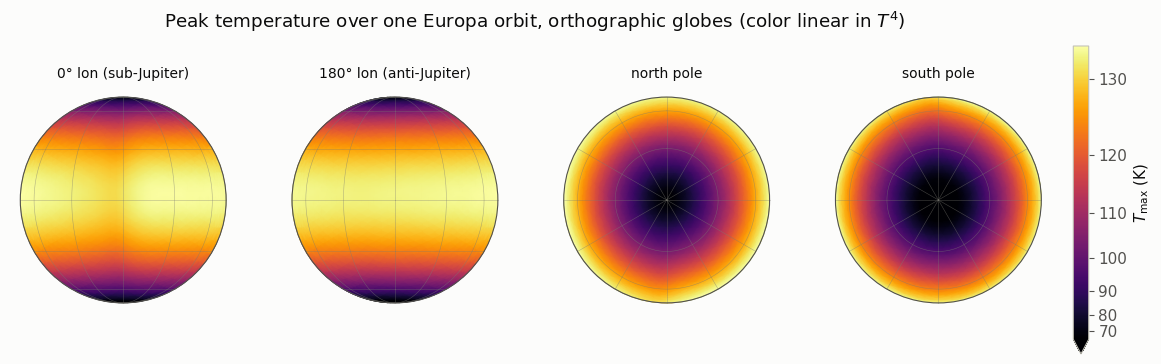

In [15]:
# Unit vertex positions (normalizing makes the renderer independent of the
# mesh's length unit) and the per-vertex temperature field.
xyz = np.stack([verts["x"], verts["y"], verts["z"]], axis=1)
xyz = xyz / np.linalg.norm(xyz, axis=1, keepdims=True)
centers = face_unit_vectors(lat, lon)
tmax_vertex = vertex_values_from_faces(tris, tmax, len(xyz))
print(f"vertex field: {len(xyz)} vertices, "
      f"{tmax_vertex.min():.1f}-{tmax_vertex.max():.1f} K "
      f"(faces {tmax.min():.1f}-{tmax.max():.1f} K -- averaging onto vertices "
      "clips the extremes slightly, as it should)")

VIEWS = [(0.0, 0.0, "0° lon (sub-Jupiter)"),
         (0.0, 180.0, "180° lon (anti-Jupiter)"),
         (90.0, 0.0, "north pole"),
         (-90.0, 0.0, "south pole")]

fig, axes = plt.subplots(1, 4, figsize=(14, 4.0))
for ax, (vlat, vlon, label) in zip(axes, VIEWS):
    art = globe(ax, xyz, tris, tmax_vertex, vlat, vlon, CMAP_T, norm_tmax, label)
cb = fig.colorbar(art, ax=axes, fraction=0.02, pad=0.02,
                  extend=clip_extend(tmax_vertex, norm_tmax))
cb.set_label(r"$T_\mathrm{max}$ (K)")
fig.suptitle("Peak temperature over one Europa orbit, orthographic globes "
             "(color linear in $T^4$)", y=0.97)
plt.show()

#### A snapshot during the eclipse

A single output step is a different kind of field from a window statistic: a
hot day side and a cold night side, spanning the whole range with a large
population at each end. It is not compressed, so it takes a plain linear
scale — the choice follows the distribution, not habit.

The panels below compare the last step before ingress with the last fully dark
step, from the same sub-solar viewpoint. The sub-solar direction is recovered
from the run's own `direct_solar` output as the flux-weighted mean of the face
directions, which needs no assumption about SPICE frames; during the eclipse
there is no sunlight to weight with, so the pre-eclipse viewpoint is reused.

step 39 (2025-01-01T17:43:59.760): sub-solar point at lat +2.6, lon +5.5 deg
  brightest face is 0.9 deg away (mesh face pitch is ~2.8 deg)


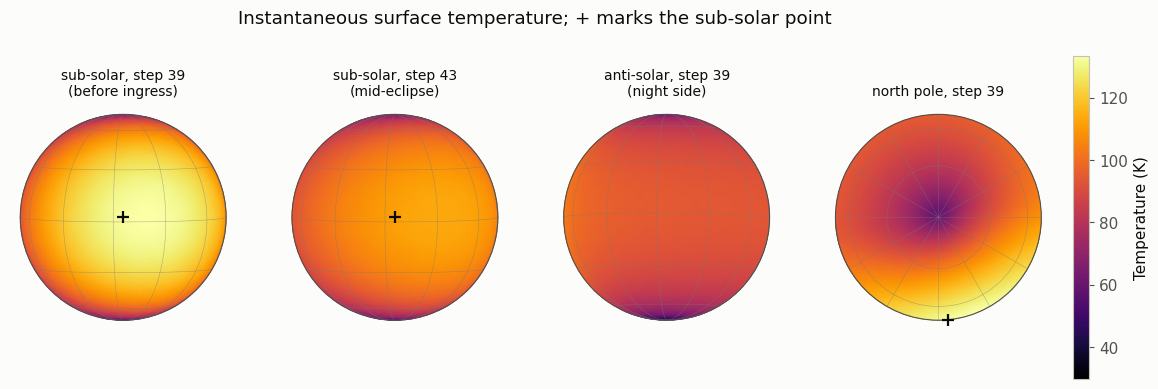


day-side faces cooled by a median of 12.9 K between step 39 and step 43 (1.8 h of full shadow)


In [16]:
STEP_BEFORE = int(eclipse_steps[0] - 1)
STEP_DARK = int(eclipse_steps[len(eclipse_steps) // 2])

ds_before = load_bin(direct_dir / f"direct_solar_{STEP_BEFORE:04d}.bin")
sub_lat, sub_lon = subsolar_latlon(ds_before, centers)
brightest = int(np.argmax(ds_before))
sep_deg = np.degrees(np.arccos(np.clip(
    centers[brightest] @ face_unit_vectors(np.array([sub_lat]), np.array([sub_lon]))[0],
    -1, 1)))
print(f"step {STEP_BEFORE} ({utc[STEP_BEFORE]}): sub-solar point at "
      f"lat {sub_lat:+.1f}, lon {sub_lon:+.1f} deg")
print(f"  brightest face is {sep_deg:.1f} deg away (mesh face pitch is "
      f"~{np.degrees(np.sqrt(4 * np.pi / len(lat))):.1f} deg)")

T_before = load_bin(temp_dir / f"temperature_{STEP_BEFORE:04d}.bin")
T_dark = load_bin(temp_dir / f"temperature_{STEP_DARK:04d}.bin")
norm_snap = mpl.colors.Normalize(min(T_before.min(), T_dark.min()),
                                 max(T_before.max(), T_dark.max()))

panels = [(T_before, sub_lat, sub_lon, f"sub-solar, step {STEP_BEFORE}\n(before ingress)"),
          (T_dark, sub_lat, sub_lon, f"sub-solar, step {STEP_DARK}\n(mid-eclipse)"),
          (T_before, -sub_lat, sub_lon + 180.0, f"anti-solar, step {STEP_BEFORE}\n(night side)"),
          (T_before, 90.0, 0.0, f"north pole, step {STEP_BEFORE}")]

fig, axes = plt.subplots(1, 4, figsize=(14, 4.2))
for ax, (field, vlat, vlon, label) in zip(axes, panels):
    art = globe(ax, xyz, tris, vertex_values_from_faces(tris, field, len(xyz)),
                vlat, vlon, CMAP_T, norm_snap, label, mark=(sub_lat, sub_lon))
cb = fig.colorbar(art, ax=axes, fraction=0.02, pad=0.02)
cb.set_label("Temperature (K)")
fig.suptitle("Instantaneous surface temperature; + marks the sub-solar point", y=0.99)
plt.show()

dayside = T_before > 100.0
print(f"\nday-side faces cooled by a median of "
      f"{np.median(T_before[dayside] - T_dark[dayside]):.1f} K between step "
      f"{STEP_BEFORE} and step {STEP_DARK} "
      f"({(t_hr[STEP_DARK] - t_hr[STEP_BEFORE]):.1f} h of full shadow)")

### 4.6 How long a spin-up is long enough?

A thermal model has to be told how long to run before anyone looks at the
answer, and `thermal.equilibration_orbits` is that setting. Choosing it too
small does not produce an obviously broken result; it produces a plausible one
carrying structure that came from the initial condition rather than from the
moon. This section shows what that looks like and how to check for it.

Two things could put longitudinal structure into the map above.

*Physical.* An eclipse happens when Europa passes directly behind Jupiter as
seen from the Sun. At that moment the Sun, Jupiter and Europa are aligned, so
the sub-solar point coincides with the sub-Jupiter point — and because Europa
rotates synchronously, the sub-Jupiter point is always the same place on the
surface. Every eclipse therefore removes sunlight from local noon at the *same*
meridian. That meridian should carry a permanent cold notch a few degrees wide.

*Numerical.* `thermal.equilibration_orbits` spins the model up before the
output window opens. If the spin-up is short, the deep layers still carry their
starting temperatures when the window begins, and they relax during it. Since
the sub-solar longitude sweeps steadily through the window, a slow drift in
time turns into a smooth ramp in longitude across the whole map.

The two respond differently to a longer spin-up: the notch stays where it is,
the ramp shrinks. The cell below re-runs the identical config with
`--equilibration-orbits 5` — the value this quickstart carried until the map
above was drawn on a scale that showed the problem — and compares it with the
20-orbit run, first as maps and then along the equatorial ring, where every
face should reach the same peak.

In [17]:
def run_sim(config_rel, extra_args=(), show=()):
    """Run ptm_thermal_sim to completion and return (stdout, wall seconds).

    Unlike section 2's live-streaming cell this one is quiet: it prints only the
    lines matching `show`, because the sections below launch several runs.
    """
    cmd = [str(BINARY), "--config", str(REPO_ROOT / config_rel), *extra_args]
    print("Running:", " ".join(str(c) for c in cmd[1:]))
    t0 = time.time()
    proc = subprocess.run(cmd, cwd=str(REPO_ROOT), stdout=subprocess.PIPE,
                          stderr=subprocess.STDOUT, text=True)
    dt = time.time() - t0
    if proc.returncode != 0:
        print(proc.stdout[-4000:])
        raise RuntimeError(f"{config_rel} exited with code {proc.returncode}")
    for line in proc.stdout.splitlines():
        if any(k in line for k in show):
            print("   ", line.strip())
    print(f"    -> exit 0 in {dt:.1f} s")
    return proc.stdout, dt

In [18]:
SHORT_EQ = "5"
SHORT_OUT = "output/quickstart_europa_diurnal_eq" + SHORT_EQ
run_sim("examples/quickstart_europa_diurnal.yaml",
        extra_args=["--equilibration-orbits", SHORT_EQ, "--output", SHORT_OUT],
        show=("Simulation completed in",))

tmax_short = load_bin(REPO_ROOT / SHORT_OUT / "statistics" / "temperature_max.bin")

# The exact equatorial ring: on an icosphere many faces share |lat| = 0 exactly.
ring = np.isclose(np.abs(lat), np.abs(lat).min(), atol=0.02)
order = np.argsort(lon[ring])
ring_lon = lon[ring][order]
print(f"\nequatorial ring: {ring.sum()} faces at |lat| = {np.abs(lat)[ring][0]:.2f} deg")
for label, field in (("equilibration_orbits = 5 ", tmax_short),
                     ("equilibration_orbits = 20", tmax)):
    r = field[ring][order]
    print(f"  {label}: Tmax {r.min():.1f}-{r.max():.1f} K "
          f"(spread {r.max() - r.min():.2f} K), coldest longitude "
          f"{ring_lon[np.argmin(r)]:+.0f} deg")

# Where was the Sun overhead during the eclipse?
lat_in, lon_in = subsolar_latlon(
    load_bin(direct_dir / f"direct_solar_{int(eclipse_steps[0]) - 1:04d}.bin"), centers)
lat_out, lon_out = subsolar_latlon(
    load_bin(direct_dir / f"direct_solar_{int(eclipse_steps[-1]) + 1:04d}.bin"), centers)
print(f"\nsub-solar longitude at eclipse ingress {lon_in:+.1f} deg, "
      f"egress {lon_out:+.1f} deg")
print("  (an eclipse aligns Sun-Jupiter-Europa, so this is the sub-Jupiter "
      "meridian, longitude 0 by definition of Europa's body-fixed frame)")

Running: --config /Users/paha3326/Projects/ptm-tutv2/examples/quickstart_europa_diurnal.yaml --equilibration-orbits 5 --output output/quickstart_europa_diurnal_eq5


    Simulation completed in 3.458 seconds (3458 ms)
    -> exit 0 in 3.7 s

equatorial ring: 64 faces at |lat| = 0.00 deg
  equilibration_orbits = 5 : Tmax 127.1-135.7 K (spread 8.66 K), coldest longitude +167 deg
  equilibration_orbits = 20: Tmax 130.5-133.5 K (spread 3.06 K), coldest longitude -5 deg

sub-solar longitude at eclipse ingress +5.5 deg, egress -7.6 deg
  (an eclipse aligns Sun-Jupiter-Europa, so this is the sub-Jupiter meridian, longitude 0 by definition of Europa's body-fixed frame)


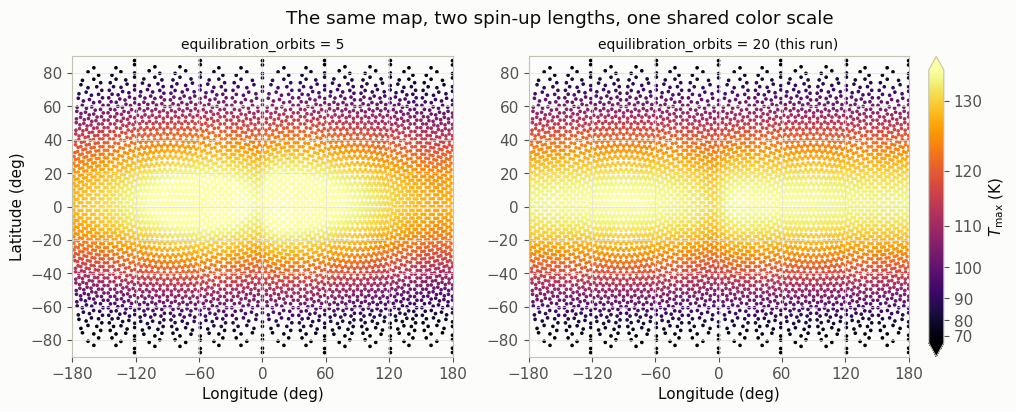

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, field, label in ((axes[0], tmax_short, "equilibration_orbits = 5"),
                         (axes[1], tmax, "equilibration_orbits = 20 (this run)")):
    sc = ax.scatter(lon, lat, c=field, cmap=CMAP_T, norm=norm_tmax, s=7, linewidths=0)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xticks(range(-180, 181, 60))
    ax.set_xlabel("Longitude (deg)")
    ax.set_title(label, fontsize=10)
    ax.grid(True, linewidth=0.5)
axes[0].set_ylabel("Latitude (deg)")
cb = fig.colorbar(sc, ax=axes, pad=0.02,
                  extend=clip_extend(np.concatenate([tmax_short, tmax]), norm_tmax))
cb.set_label(r"$T_\mathrm{max}$ (K)")
fig.suptitle("The same map, two spin-up lengths, one shared color scale", y=1.0)
plt.show()

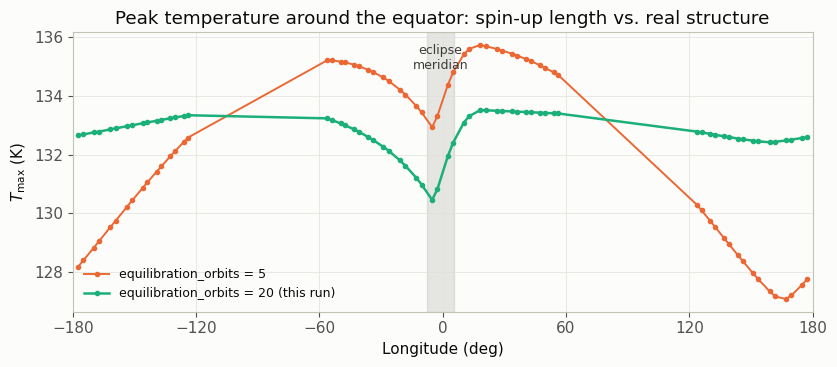

In [20]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(ring_lon, tmax_short[ring][order], "o-", ms=3, lw=1.4,
        color=ACCENT_ORANGE, label="equilibration_orbits = 5")
ax.plot(ring_lon, tmax[ring][order], "o-", ms=3, lw=1.8,
        color=ACCENT_AQUA, label="equilibration_orbits = 20 (this run)")
ax.axvspan(lon_out, lon_in, color=NEUTRAL_BAND, alpha=0.2, zorder=0)
_ymin, _ymax = ax.get_ylim()
ax.text(0.5 * (lon_in + lon_out), _ymax - 0.04 * (_ymax - _ymin), "eclipse\nmeridian",
        ha="center", va="top", fontsize=9, color="#3d3c37")
ax.set_xlabel("Longitude (deg)")
ax.set_ylabel(r"$T_\mathrm{max}$ (K)")
ax.set_xlim(-180, 180)
ax.set_xticks(range(-180, 181, 60))
ax.set_title("Peak temperature around the equator: spin-up length vs. real structure")
ax.grid(True, linewidth=0.5)
ax.legend(frameon=False, loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

The broad ramp is spin-up, not Europa: it collapses when the model is given
more orbits to forget its starting state. What survives is the narrow notch at
the sub-Jupiter meridian, sitting exactly where the eclipse puts the Sun
overhead — a real feature of a synchronously rotating moon that is eclipsed
once per orbit, in the same place every time.

This is why the config ships with `equilibration_orbits: 20` rather than the 5
that the surface layer alone would need. Twenty is not exact either: doubling
it again to 40 still moves the field by a few tenths of a kelvin RMS. Choose
the spin-up length by the accuracy the question needs, and check it the way
this section does — by lengthening it and looking at what changes.

## 5. Interpretation

**The eclipse's thermal fingerprint.** The shaded band marks ~2.7 h where
direct solar flux is *exactly* zero, body-wide: Europa is inside Jupiter's
shadow, so the whole day side loses the Sun at once. The selected face's
temperature does not follow the flux to zero — printed above, it cools by
roughly 20 K over those ~2.7 h, limited by the same thin conductive skin
layer that governs the normal diurnal cycle (below). When sunlight returns,
the temperature only partially recovers: the post-eclipse local peak lands
below the pre-eclipse peak, because the eclipse cut off part of the rise
toward local noon. The flux discontinuity (full daytime flux to zero in one
SPICE-geometry transition) is also why `docs/thermal-model.md` describes an
"event-aware" adaptive timestep controller for resolving eclipses.

**Ice thermal inertia.** Europa's default porous-ice regolith
($k_s=0.0096$ W/m/K, $\rho_s=500$ kg/m³, $c_p(100\,\mathrm{K})\approx750$
J/kg/K) gives a diurnal thermal skin depth
$\delta=\sqrt{\kappa P/\pi}\approx5$ cm for the 3.55-day period. A thin skin
depth means the surface layer's heat content is small: it responds quickly
(the eclipse cooling printed above, in under 3 hours), but it also stores
comparatively little heat to buffer the night. The layers *below* the skin
depth are a separate matter, and they are the ones section 4.6 has to spin
up for twenty orbits.

**Why Europa's night stays warm relative to its day.** The printed comparison
above quantifies it: the Moon's median-face day/night ratio
($T_\mathrm{min}/T_\mathrm{max}$) is around 0.25; Europa's is around 0.7.
The main reason is not the material — the thermal inertias are broadly
comparable — but the night length: **Europa's night is only 1.775 Earth days
long**, against the Moon's ~14.75-day lunar night, so there is roughly 8x
less time for stored daytime heat to radiate away before the next sunrise.
The run itself shows the size of the effect: the handful of
**permanently-unlit near-polar faces** (printed in section 3) sit at the
zero-insolation geothermal floor $T=(Q_b/\epsilon\sigma)^{1/4}\approx28$ K,
while a typical illuminated face bottoms out near the median
`temperature_min` printed in section 3 — some 60 K of retained daytime heat
that the short Europa night has not had time to shed. It is the same mechanism as the Moon's nighttime plateau,
proportionally much larger here because of the orbital period, not the
material properties.

**Never-illuminated faces as a built-in floor check.** A face that receives
zero flux, ever, should sit at the internal-heat-flux-only equilibrium
$T=(Q_b/\epsilon\sigma)^{1/4}$. With this config's $Q_b=0.03$ W/m² and
$\epsilon=0.9$, that predicts 27.7 K — matching the ~30 K observed for those
faces to within the coarse-mesh grazing-incidence residual.

## 6. Exercises

1. **Change the albedo, uniformly.** `thermophysical.albedo_override` (a
   top-level key next to `use_default_albedo`) replaces the built-in Bond
   albedo 0.5 with any value $\ge0$ — e.g. `albedo_override: 0.3` for a
   darker, non-ice-dominated surface. Lower albedo absorbs more flux; re-run
   and compare both the peak and whether the night-side floor moves as much
   as the peak does (thermal-inertia damping should make the night respond
   less).

2. **Eclipse on/off comparison.** The eclipse is not a config flag — it is
   real SPICE geometry, and every full-orbit window contains exactly one.
   For an eclipse-free comparison window, shorten and shift the run: try
   `start_time: '2025-01-02T00:00:00'` with `duration_days: 1.5` (adjust
   `timesteps` down proportionally, e.g. to `~81`, to keep the same
   ~26.6 min cadence) — this window sits entirely between the eclipse this
   notebook found and the next one (one full orbit, ~85.2 h, later). Apply
   the same face-selection logic from section 4 and compare the
   *uninterrupted* peak temperature to this run's post-eclipse peak.

3. **`include_primary_reflection: false`.** Set it false and re-run. In the
   printed final "Results" block, `Primary reflected` flux drops to ~0 while
   `Primary IR` is essentially unchanged — the asymmetric gating described
   in section 1.

4. **Resolution.** Bump `mesh.resolution: 4` to `5` (5120 → 20,480 faces) or
   `6` (81,920 faces, the resolution the `configs/europa_ico6_*.yaml`
   production configs use) for a sharper map. Check
   `scripts/ptm_mem_estimate.py --faces 20480 --steps 192` before running —
   still laptop-sized, but no longer instant.

## Version

The binary and commit that produced the numbers in this notebook.


In [21]:
import hashlib
import subprocess as sp

md5 = hashlib.md5(BINARY.read_bytes()).hexdigest()
print("Binary:", BINARY)
print("MD5:   ", md5)

try:
    commit = sp.run(
        ["/Library/Developer/CommandLineTools/usr/bin/git", "rev-parse", "HEAD"],
        cwd=str(REPO_ROOT), capture_output=True, text=True, check=True,
    ).stdout.strip()
    branch = sp.run(
        ["/Library/Developer/CommandLineTools/usr/bin/git", "rev-parse", "--abbrev-ref", "HEAD"],
        cwd=str(REPO_ROOT), capture_output=True, text=True, check=True,
    ).stdout.strip()
    print("Commit:", commit, f"({branch})")
except Exception as exc:  # pragma: no cover -- version info is best-effort
    print("(git information unavailable in this environment:", exc, ")")

print(f"\nWall time of the run in section 2: {wall_time_s:.1f} s")


Binary: /Users/paha3326/Projects/ptm-tutv2/build/bin/ptm_thermal_sim
MD5:    d2c20f36b9232f59044f6c7bda63fe30
Commit: 8ba2ab91223b70784d7c0368367033506e1a043e (feat/tutorials-v2)

Wall time of the run in section 2: 9.7 s
